[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_03/MFM_ch3_fama_macbeth/MFM_ch3_fama_macbeth.ipynb)

# MFM_ch3_fama_macbeth

Fama-MacBeth two-pass regressions of the CAPM, FF3 and FF5 on the 25 size x book-to-market portfolios (1963-2026) with Fama-MacBeth, Newey-West, Shanken and Kan-Robotti-Shanken (misspecification-robust) standard errors; the same procedure on 16 sector and factor ETFs (Seminar 3, B5).

*Modelling Financial Markets (MFM), Chapter 3: Factor Models and Asset Pricing. Author: Daniel Traian Pele.*

In [1]:
import os
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

## Data

Market prices from the course repository (`data/market`); factor and portfolio returns from the Kenneth French Data Library.

In [2]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
FRENCH = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'

SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']        # from Dec 1998
SECTORS_ALL = SECTORS + ['XLRE', 'XLC']                                           # XLRE 2015, XLC 2018
SECTOR_NAMES = {'XLB': 'Materials', 'XLE': 'Energy', 'XLF': 'Financials', 'XLI': 'Industrials',
                'XLK': 'Technology', 'XLP': 'Cons. staples', 'XLU': 'Utilities', 'XLV': 'Health care',
                'XLY': 'Cons. discretionary', 'XLRE': 'Real estate', 'XLC': 'Communication'}
FACTOR_ETFS = ['MTUM', 'VLUE', 'QUAL', 'USMV', 'IWM', 'IWD', 'IWF']
BVB = ['TLV', 'SNP', 'BRD', 'TGN', 'FP', 'SNG', 'H2O', 'SNN', 'EL', 'DIGI', 'TEL']
BVB_NAMES = {'TLV': 'Banca Transilvania', 'SNP': 'OMV Petrom', 'BRD': 'BRD-GSG', 'TGN': 'Transgaz',
             'FP': 'Fondul Proprietatea', 'SNG': 'Romgaz', 'H2O': 'Hidroelectrica', 'SNN': 'Nuclearelectrica',
             'EL': 'Electrica', 'DIGI': 'Digi', 'TEL': 'Transelectrica'}

_CACHE = {}


def read_market(symbol):
    """Daily prices of one asset from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def price(symbol):
    """Price used: adjusted close for ETFs and stocks, close for indices."""
    d = read_market(symbol)
    col = 'close' if symbol.endswith('.INDX') or symbol == 'BET' else 'adjusted_close'
    s = d[col].astype(float)
    return s[s > 0].rename(symbol)


def prices(symbols, start=None, end=None):
    """Prices aligned on the common days (multi-asset analyses align prices before taking returns)."""
    p = pd.concat([price(s) for s in symbols], axis=1).dropna()
    return p.loc[start:end]


def log_returns(p):
    """Log returns of an already aligned table (common days)."""
    return np.log(p).diff().dropna()


# =============================================================================
# KENNETH FRENCH DATA LIBRARY
# =============================================================================
FILES = {
    ('ff3', 'M'): 'F-F_Research_Data_Factors_CSV.zip',
    ('ff3', 'D'): 'F-F_Research_Data_Factors_daily_CSV.zip',
    ('ff5', 'M'): 'F-F_Research_Data_5_Factors_2x3_CSV.zip',
    ('ff5', 'D'): 'F-F_Research_Data_5_Factors_2x3_daily_CSV.zip',
    ('mom', 'M'): 'F-F_Momentum_Factor_CSV.zip',
    ('mom', 'D'): 'F-F_Momentum_Factor_daily_CSV.zip',
    ('p25', 'M'): '25_Portfolios_5x5_CSV.zip',
    ('ind10', 'M'): '10_Industry_Portfolios_CSV.zip',
    ('ind30', 'M'): '30_Industry_Portfolios_CSV.zip',
    ('p100', 'M'): '100_Portfolios_10x10_CSV.zip',
    # univariate sorts (first table: value-weighted), Jensen-Kelly-Pedersen case study
    ('ME', 'M'): 'Portfolios_Formed_on_ME_CSV.zip',
    ('BE-ME', 'M'): 'Portfolios_Formed_on_BE-ME_CSV.zip',
    ('OP', 'M'): 'Portfolios_Formed_on_OP_CSV.zip',
    ('INV', 'M'): 'Portfolios_Formed_on_INV_CSV.zip',
    ('E-P', 'M'): 'Portfolios_Formed_on_E-P_CSV.zip',
    ('CF-P', 'M'): 'Portfolios_Formed_on_CF-P_CSV.zip',
    ('D-P', 'M'): 'Portfolios_Formed_on_D-P_CSV.zip',
    ('AC', 'M'): 'Portfolios_Formed_on_AC_CSV.zip',
    ('NI', 'M'): 'Portfolios_Formed_on_NI_CSV.zip',
    ('BETA', 'M'): 'Portfolios_Formed_on_BETA_CSV.zip',
    ('VAR', 'M'): 'Portfolios_Formed_on_VAR_CSV.zip',
    ('RESVAR', 'M'): 'Portfolios_Formed_on_RESVAR_CSV.zip',
    ('PRIOR_12_2', 'M'): '10_Portfolios_Prior_12_2_CSV.zip',
    ('PRIOR_1_0', 'M'): '10_Portfolios_Prior_1_0_CSV.zip',
    ('PRIOR_60_13', 'M'): '10_Portfolios_Prior_60_13_CSV.zip',
    # reversal factors, factor-momentum case study (Ehsani & Linnainmaa, 2022)
    ('strev', 'M'): 'F-F_ST_Reversal_Factor_CSV.zip',
    ('ltrev', 'M'): 'F-F_LT_Reversal_Factor_CSV.zip',
}


def _parse_first_table(text, date_len):
    """First table of a French data set: header ',col1,col2...', then rows YYYYMM(DD),values."""
    lines = text.splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith(',') and len(l.split(',')) > 1)
    cols = [c.strip() for c in lines[i].split(',')[1:]]
    rows = []
    for l in lines[i + 1:]:
        parts = [x.strip() for x in l.split(',')]
        if not parts or len(parts[0]) != date_len or not parts[0].isdigit():
            break
        rows.append([parts[0]] + [float(x) for x in parts[1:]])
    df = pd.DataFrame(rows, columns=['date'] + cols)
    fmt = '%Y%m' if date_len == 6 else '%Y%m%d'
    df['date'] = pd.to_datetime(df['date'], format=fmt)
    if date_len == 6:
        df['date'] = df['date'] + pd.offsets.MonthEnd(0)
    df = df.set_index('date')
    return df.replace([-99.99, -999.0], np.nan) / 100.0          # percent -> decimal


def french(name='ff5', freq='M'):
    """Fama-French factors / momentum / portfolios, in decimals (0.01 = 1%)."""
    key = (name, freq)
    if key in _CACHE:
        return _CACHE[key]
    url = FRENCH + FILES[key]
    raw = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}),
                                 timeout=120).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    text = z.read(z.namelist()[0]).decode('latin-1')
    df = _parse_first_table(text, 6 if freq == 'M' else 8)
    df.columns = [c.replace('Mom', 'MOM').strip() for c in df.columns]
    _CACHE[key] = df
    return df


def factors(freq='M'):
    """Mkt-RF, SMB, HML, RMW, CMA, RF, MOM and SMB_FF3 over the common period.

    The five-factor SMB (sorts on B/M, profitability and investment) enters FF5;
    SMB_FF3 is the published three-factor SMB (2x3 sorts on size and B/M),
    used in FF3 and Carhart. HML, Mkt-RF and RF are the same in the two data sets.
    """
    f3 = french('ff3', freq)[['SMB']].rename(columns={'SMB': 'SMB_FF3'})
    return pd.concat([french('ff5', freq), french('mom', freq), f3], axis=1).dropna()


# =============================================================================
# REGRESSIONS
# =============================================================================
def ols_hac(y, X, lags=None, const=True):
    """OLS with Newey-West (Bartlett) standard errors. Returns (coef, se, t, resid, r2)."""
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    if const:
        X = np.column_stack([np.ones(len(y)), X])
    n, k = X.shape
    if lags is None:
        lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    u = X * e[:, None]
    S = u.T @ u
    for l in range(1, lags + 1):
        w = 1 - l / (lags + 1)
        G = u[l:].T @ u[:-l]
        S += w * (G + G.T)
    V = XtX_inv @ S @ XtX_inv
    se = np.sqrt(np.diag(V))
    r2 = 1 - e.var() / y.var()
    return b, se, b / se, e, r2


def grs_test(excess, market_excess):
    """Gibbons-Ross-Shanken (1989) test of alpha = 0 on N assets, one factor.

    Sigma and the factor variance are maximum-likelihood estimators (division by T);
    under i.i.d. Normal residuals, W ~ F(N, T - N - 1) exactly.
    """
    from scipy import stats
    R = np.asarray(excess, float)
    f = np.asarray(market_excess, float)
    T, N = R.shape
    X = np.column_stack([np.ones(T), f])
    B = np.linalg.lstsq(X, R, rcond=None)[0]
    alpha = B[0]
    E = R - X @ B
    Sigma = E.T @ E / T
    mu, s2 = f.mean(), f.var(ddof=0)
    stat = (T - N - 1) / N * (alpha @ np.linalg.solve(Sigma, alpha)) / (1 + mu ** 2 / s2)
    p = 1 - stats.f.cdf(stat, N, T - N - 1)
    return stat, p, alpha, B[1]

## Style and helpers

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
PALETTE = [MainBlue, IDAred, Forest, Amber, Orange, Purple, Crimson, '#795548', '#17A2B8', '#6F42C1', '#20C997']

# models: FF3 and Carhart use the published three-factor SMB; FF5 uses the five-factor SMB
FF3 = ['Mkt-RF', 'SMB_FF3', 'HML']
CARHART = FF3 + ['MOM']
FF5 = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
FF6 = FF5 + ['MOM']

SEED = 42
MAX_ABS_RET = 0.5        # data-error threshold for the BVB series (daily log return)
END = '2026-07-31'       # last month of the monthly sample used in the chapter (T = 757 months from July 1963)


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def monthly_excess(symbols, start='1999-01-01'):
    """Monthly simple excess returns over RF (one-month T-bill), on the common months."""
    p = prices(symbols).resample('ME').last()
    r = p.pct_change().dropna()
    F = factors('M')
    idx = r.index.intersection(F.index)
    r = r.loc[idx].loc[start:END]
    F = F.loc[r.index]
    return r.sub(F['RF'], axis=0), F


def daily_excess_one(symbol, start=None):
    """Daily excess return of a single asset, on the factor calendar.

    Only days with a price on the previous trading day are kept
    (otherwise the return would span several days and the factors only one).
    """
    s = price(symbol)
    F = factors('D').loc[:END]                         # same sample end as the monthly data
    s = s.loc[s.index.isin(F.index)]
    cal = pd.Series(np.arange(len(F)), index=F.index)
    pos = cal.loc[s.index].values
    r = s.pct_change()
    consecutive = np.r_[False, np.diff(pos) == 1]
    r = r[consecutive].dropna()
    if start:
        r = r.loc[start:]
    Fx = F.loc[r.index]
    return (r - Fx['RF']).rename(symbol), Fx


def daily_excess(symbols, start=None):
    """Compatibility: dictionary {symbol: (excess, factors)} on each asset's calendar."""
    return {s: daily_excess_one(s, start) for s in symbols}

SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
FACTOR_ETFS = ['MTUM', 'VLUE', 'QUAL', 'USMV', 'IWM', 'IWD', 'IWF']

## Analysis

In [4]:
def sml_data(start='1963-07-31'):
    F = factors('M')
    P = french('p25', 'M').loc[start:END]
    Fx = F.loc[P.index]
    ex = P.sub(Fx['RF'], axis=0)
    mk = Fx['Mkt-RF']
    rows = []
    for c in ex.columns:
        b, se, t, e, r2 = ols_hac(ex[c].values, mk.values)
        rows.append((c, b[1], b[0] * 12, t[0], ex[c].mean() * 12))
    res = pd.DataFrame(rows, columns=['port', 'beta', 'alpha', 't_alpha', 'avg']).set_index('port')
    return res, ex, mk


def fama_macbeth(ex, F, fac, nw_lags=6):
    """Pass 1: full-sample betas; pass 2: monthly cross-sectional regressions."""
    X = F[fac].values
    B = np.linalg.lstsq(np.column_stack([np.ones(len(X)), X]), ex.values, rcond=None)[0][1:].T   # N x K
    lam = []
    for t in range(len(ex)):
        Z = np.column_stack([np.ones(B.shape[0]), B])
        lam.append(np.linalg.lstsq(Z, ex.values[t], rcond=None)[0])
    lam = np.array(lam)                                   # T x (1+K)
    mean = lam.mean(0)
    se_fm = lam.std(0, ddof=1) / np.sqrt(len(lam))
    se_nw = np.array([ols_hac(lam[:, j], np.zeros((len(lam), 0)), lags=nw_lags)[1][0] for j in range(lam.shape[1])])
    # Shanken (1992) correction: the FM variance already contains Sigma_f / T (factor variation);
    # only the remainder (the idiosyncratic part) is multiplied by (1 + c), c = lambda' Sigma_f^-1 lambda:
    # Var_Sh = (1 + c) (Var_FM - Sigma_f* / T) + Sigma_f* / T, Sigma_f* = Sigma_f bordered with zeros for the intercept
    Sf = np.atleast_2d(np.cov(X.T))
    c = mean[1:] @ np.linalg.solve(Sf, mean[1:])
    sf_diag = np.r_[0.0, np.diag(Sf)] / len(lam)
    se_sh = np.sqrt((1 + c) * (se_fm ** 2 - sf_diag) + sf_diag)
    return pd.DataFrame({'lambda': mean * 12, 'se_fm': se_fm * 12, 'se_nw': se_nw * 12, 'se_shanken': se_sh * 12,
                         'factor_mean': np.r_[np.nan, X.mean(0) * 12]}, index=['const'] + fac)


def fig_fama_macbeth():
    res, ex, mk = sml_data()
    F = factors('M').loc[ex.index]
    models = {'CAPM': ['Mkt-RF'], 'FF3': FF3, 'FF5': FF5}
    out = {k: fama_macbeth(ex, F, v) for k, v in models.items()}
    fig, ax = plt.subplots(figsize=(6.8, 3.0))
    labels, x0 = [], 0
    for k, c in zip(models, [MainBlue, Amber, Forest]):
        d = out[k]
        xs = np.arange(len(d)) + x0
        ax.errorbar(xs, d['lambda'], yerr=1.96 * d['se_shanken'], fmt='o', color=c, capsize=2, lw=0.8, label=k)
        ax.plot(xs[1:], d['factor_mean'].iloc[1:], 'x', color=Purple, ms=5)
        labels += [f'{k}: {n.replace("SMB_FF3", "SMB")}' for n in d.index]
        x0 += len(d) + 1
    ax.plot([], [], 'x', color=Purple, label='Time-series mean of the factor')
    ax.axhline(0, color=Gray, lw=0.5)
    ticks = []
    x0 = 0
    for k in models:
        ticks += list(np.arange(len(out[k])) + x0)
        x0 += len(out[k]) + 1
    ax.set_xticks(ticks, [l.split(': ')[1] for l in labels], rotation=45, fontsize=7)
    ax.set_ylabel('Premium (ann.)\n95% CI (Shanken)')
    ax.set_title('Fama-MacBeth risk premia on 25 size x B/M portfolios, 1963-2026', fontsize=9, loc='left')
    legend_outside_bottom(ax, ncol=4, y=-0.3)
    plt.tight_layout()
    save_fig('ch3_fama_macbeth')
    r = {k: v.round(4).reset_index().to_dict(orient='records') for k, v in out.items()}
    # dispersion of the pass-1 market betas across the 25 portfolios (identification of the market premium)
    r['market_betas'] = {}
    for k, v in models.items():
        b = np.linalg.lstsq(np.column_stack([np.ones(len(ex)), F[v].values]), ex.values, rcond=None)[0][1]
        r['market_betas'][k] = dict(min=float(b.min()), max=float(b.max()), sd=float(b.std(ddof=1)))
    return r


def two_pass_gmm(ex, F, fac, lags=0):
    """Two passes as an exactly identified GMM: moments (R - a - B f) x (1, f) and X'(R - X gamma), X = [1, B].

    Returns gamma (annualised) and the standard errors:
      * 'krs'    : misspecification-robust (Kan, Robotti & Shanken, 2013) -- full derivative,
                   including the term with the pricing errors e = mu - X gamma;
      * 'correct': the same formula with e = 0 (model assumed correct; Jagannathan & Wang, 1998).
    lags > 0: Newey-West (Bartlett) S matrix; lags = 0: serially uncorrelated moments.
    """
    R = np.asarray(ex, float)
    Fm = np.asarray(F[fac], float)
    T, N = R.shape
    K = Fm.shape[1]
    Z = np.column_stack([np.ones(T), Fm])                      # T x (K+1)
    AB = np.linalg.lstsq(Z, R, rcond=None)[0]                  # (K+1) x N: a, B
    B = AB[1:].T                                               # N x K
    X = np.column_stack([np.ones(N), B])
    mu = R.mean(0)
    gam = np.linalg.lstsq(X, mu, rcond=None)[0]
    npar = (K + 1) * N + K + 1

    def unpack(th):
        ab = th[:(K + 1) * N].reshape(K + 1, N)
        return ab, th[(K + 1) * N:]

    def gbar(th, target):
        ab, g = unpack(th)
        E = R - Z @ ab
        g1 = (Z.T @ E / T).ravel()                            # (K+1) x N
        Xb = np.column_stack([np.ones(N), ab[1:].T])
        g2 = Xb.T @ (target - Xb @ g)
        return np.r_[g1, g2]

    th0 = np.r_[AB.ravel(), gam]

    def jac(target):
        J = np.empty((npar, npar))
        h = 1e-6
        for j in range(npar):
            d = np.zeros(npar)
            d[j] = h
            J[:, j] = (gbar(th0 + d, target) - gbar(th0 - d, target)) / (2 * h)
        return J

    # individual moment contributions (their sample mean is zero)
    E = R - Z @ AB
    g1t = (Z[:, :, None] * E[:, None, :]).reshape(T, -1)
    g2t = (R - X @ gam) @ X
    G = np.column_stack([g1t, g2t])
    S = G.T @ G / T
    for l in range(1, lags + 1):
        w = 1 - l / (lags + 1)
        C = G[l:].T @ G[:-l] / T
        S += w * (C + C.T)
    out = {}
    for lab, target in [('krs', mu), ('correct', X @ gam)]:
        Ji = np.linalg.inv(jac(target))
        V = Ji @ S @ Ji.T / T
        out[lab] = np.sqrt(np.diag(V)[-(K + 1):]) * 12
    e = mu - X @ gam
    return dict(gamma=gam * 12, se_krs=out['krs'], se_correct=out['correct'],
                pricing_error_rms=float(np.sqrt((e ** 2).mean()) * 12))


def fm_krs_table(ex, F, fac):
    """Fama-MacBeth (FM, NW 6, Shanken) plus Kan-Robotti-Shanken errors, on the same assets.

    se_krs: misspecification-robust, serially uncorrelated moments; se_krs_nw: the same with a
    Newey-West (6 lags) S matrix, robust to misspecification and to serial dependence.
    """
    d = fama_macbeth(ex, F, fac)
    k = two_pass_gmm(ex.values, F, fac)
    d['se_krs'] = k['se_krs']
    d['se_krs_nw'] = two_pass_gmm(ex.values, F, fac, lags=6)['se_krs']
    d['se_correct'] = k['se_correct']
    return d


def b5_fama_macbeth():
    E = [s + '.US' for s in SECTORS] + [e + '.US' for e in FACTOR_ETFS]
    ex, F = monthly_excess(E, start='2013-08-01')
    out = fm_krs_table(ex, F, FF3)
    return dict(T=len(ex), N=len(E), start=str(ex.index[0].date()), end=str(ex.index[-1].date()),
                table=out.round(4).reset_index().to_dict(orient='records'))

## Run

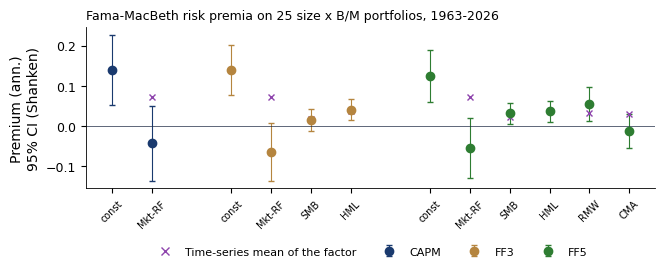

   saved ch3_fama_macbeth


,index,lambda,se_fm,se_nw,se_shanken,factor_mean,se_krs,se_krs_nw,se_correct
0,const,0.0099,0.0543,0.0440,0.0567,NaN,0.0596,0.0494,0.0583
1,Mkt-RF,0.1162,0.0673,0.0563,0.0692,0.1240,0.0688,0.0572,0.0682
2,SMB_FF3,-0.0378,0.0283,0.0254,0.0286,-0.0195,0.0303,0.0287,0.0292
3,HML,-0.0352,0.0428,0.0458,0.0436,-0.0057,0.0434,0.0503,0.0430


In [5]:
fig_fama_macbeth()
b5 = b5_fama_macbeth()
pd.DataFrame(b5['table'])

![ch3_fama_macbeth](./ch3_fama_macbeth.png)

Output: `ch3_fama_macbeth.pdf`